# Tea Leaf Disease Classifier - Transfer Learning with ResNet18

**What this notebook does, in plain words:** we have photos of tea leaves
sorted into 7 folders - one healthy, six sick (disease or pest). We teach a
computer-vision model to look at a new photo and guess which of the 7
folders it belongs to. Instead of teaching it from zero, we start from
**ResNet18**, a model that already learned to recognise shapes, edges and
textures from millions of general photos, and we only teach it the
tea-leaf-specific part. This is called **transfer learning** - borrowing
what one model already knows instead of starting from scratch.

Runs top to bottom like a Colab notebook: just execute each cell in order.


## 1. Setup

**What we're doing here:** importing the tools (libraries) we need, picking
a fixed "random seed" so re-running this notebook gives the same split and
roughly the same results each time, and checking whether we have a GPU
(we probably don't on a laptop, so we'll use the CPU - slower, but it works
fine for this dataset size).


In [77]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cpu


## 2. Where the data lives, and the settings we'll use

**What we're doing here:** pointing the notebook at the dataset folder
(already downloaded by `dataset/download_dataset.py`), and writing down
every "knob" we might want to tune later (image size, batch size, how many
training passes/epochs) in one place instead of scattering them through
the notebook.


In [78]:
DATA_DIR = Path("dataset/data/teaLeafBD/teaLeafBD")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

IMG_SIZE = 224          # ResNet expects (at least roughly) 224x224 pictures
BATCH_SIZE = 32       # how many pictures we show the model at once
EPOCHS = 6             # how many full passes we make over the training photos
LEARNING_RATE = 1e-3
VAL_SIZE = 0.15         # 15% of the data held back to check progress during training
TEST_SIZE = 0.15        # another 15% held back, touched only once, at the very end

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR}. Run dataset/download_dataset.py first."


## 3. Explore the data (EDA)

**What we're doing here:** before training anything, we look at what we
actually have - how many classes, how many photos per class, and what the
photos look like. This matters because if one class has far fewer photos
than the others, the model can get lazy and just guess the common classes.


In [79]:
class_dirs = sorted([d for d in DATA_DIR.iterdir() if d.is_dir()])
class_names = [d.name for d in class_dirs]
print(f"Found {len(class_names)} classes:")
for c in class_names:
    print(" -", c)


Found 7 classes:
 - 1. Tea algal leaf spot
 - 2. Brown Blight
 - 3. Gray Blight
 - 4. Helopeltis
 - 5. Red spider
 - 6. Green mirid bug
 - 7. Healthy leaf


In [80]:
# Count how many photos are in each class folder
counts = {d.name: len(list(d.glob("*.*"))) for d in class_dirs}
counts_df = pd.DataFrame(sorted(counts.items(), key=lambda x: x[0]), columns=["class", "num_images"])
counts_df


,class,num_images
0,1. Tea algal leaf spot,418
1,2. Brown Blight,506
2,3. Gray Blight,1013
3,4. Helopeltis,607
4,5. Red spider,515
5,6. Green mirid bug,1282
6,7. Healthy leaf,935


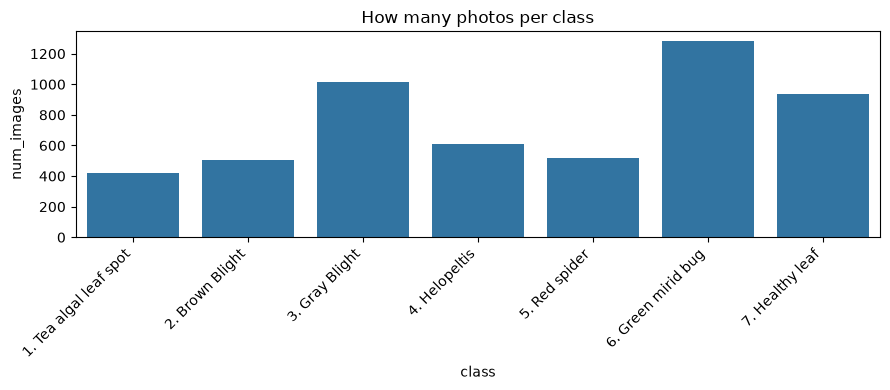

In [81]:
# A simple bar chart so class imbalance jumps out visually
plt.figure(figsize=(9, 4))
sns.barplot(data=counts_df, x="class", y="num_images")
plt.xticks(rotation=45, ha="right")
plt.title("How many photos per class")
plt.tight_layout()
plt.show()


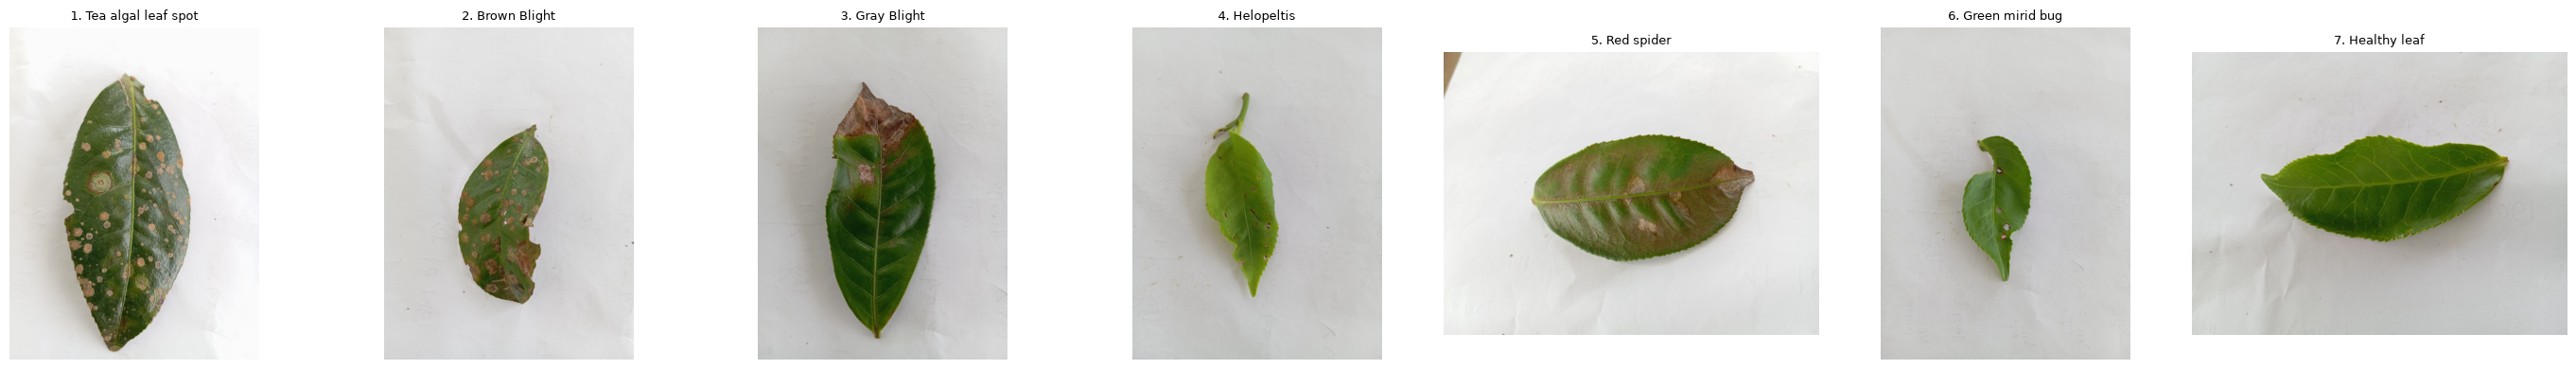

In [82]:
# Peek at a few example photos, one per class, so we know what we're working with
fig, axes = plt.subplots(1, len(class_dirs), figsize=(4 * len(class_dirs), 4))
for ax, d in zip(axes, class_dirs):
    sample_path = next(d.glob("*.*"))
    img = Image.open(sample_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(d.name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 4. Build the file list and split it into train / validation / test

**What we're doing here:** making one big list of "this photo -> this
class", then cutting it into three piles:
- **train** (70%): what the model actually learns from
- **validation** (15%): checked after every epoch, just to see how training
  is going (never used to update the model's weights)
- **test** (15%): locked away and only looked at once, at the very end, to
  get an honest score on photos the model has never seen in any way

We split in a "stratified" way, meaning each pile keeps roughly the same
mix of classes as the full dataset.


In [83]:
all_paths, all_labels = [], []
for idx, d in enumerate(class_dirs):
    for f in d.glob("*.*"):
        all_paths.append(str(f))
        all_labels.append(idx)

print(f"Total images: {len(all_paths)}")

train_paths, rest_paths, train_labels, rest_labels = train_test_split(
    all_paths, all_labels, test_size=(VAL_SIZE + TEST_SIZE),
    stratify=all_labels, random_state=SEED,
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    rest_paths, rest_labels, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    stratify=rest_labels, random_state=SEED,
)

print(f"Train: {len(train_paths)}  Val: {len(val_paths)}  Test: {len(test_paths)}")


Total images: 5276
Train: 3693  Val: 791  Test: 792


## 5. Data augmentation and preprocessing

**What we're doing here:** "augmentation" means making small random changes
to each training photo - flip it, rotate it a little, tweak its
brightness/contrast. The photo still shows the same disease, but the pixels
are different each time the model sees it. This teaches the model to
recognise the disease itself rather than memorising exact photos, which
helps it generalise to brand-new leaves.

We only augment the **training** photos. Validation and test photos are
resized and normalised the same simple way every time, so our evaluation
numbers stay consistent and comparable.

"Normalising" with the ImageNet mean/std below just rescales pixel values
into the range ResNet18 was originally trained on.


In [84]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


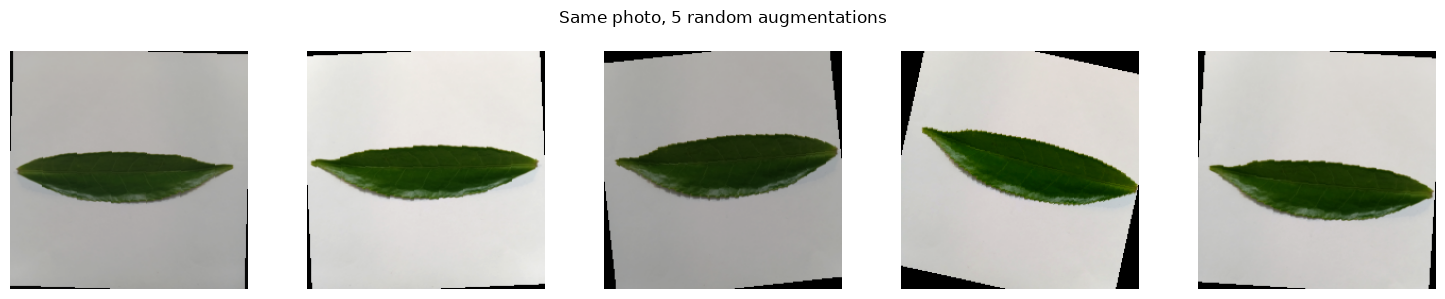

In [85]:
# Show what augmentation actually does to one photo: same leaf, five random versions
sample_img = Image.open(train_paths[0]).convert("RGB")
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax in axes:
    augmented = train_transform(sample_img)
    # undo the normalisation just so it displays with sane colours
    unnorm = augmented * torch.tensor(IMAGENET_STD).view(3, 1, 1) + torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    ax.imshow(unnorm.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.axis("off")
fig.suptitle("Same photo, 5 random augmentations")
plt.tight_layout()
plt.show()


## 6. Dataset and DataLoader

**What we're doing here:** PyTorch needs two small building blocks to feed
photos to the model efficiently:
- a `Dataset` that knows how to open the *n*-th photo and return it with its
  label
- a `DataLoader` that wraps the dataset and serves it up in shuffled
  batches (groups of `BATCH_SIZE` photos at a time)


In [86]:
class TeaLeafDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.transform(img)
        return img, self.labels[idx]


train_ds = TeaLeafDataset(train_paths, train_labels, train_transform)
val_ds = TeaLeafDataset(val_paths, val_labels, eval_transform)
test_ds = TeaLeafDataset(test_paths, test_labels, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Batches -> train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")


Batches -> train: 116  val: 25  test: 25


## 7. The model: ResNet18 with transfer learning

**What we're doing here:**
1. Download **ResNet18** already trained on ImageNet (1.2 million general
   photos, 1000 everyday categories like "dog", "car", "mug").
2. **Freeze** every layer of it - meaning "don't change what you already
   learned about shapes, edges and textures".
3. Replace its final decision layer (which used to choose between 1000
   ImageNet categories) with a brand-new, untrained layer that chooses
   between our 7 tea-leaf categories.
4. Only that new final layer gets trained. Everything else stays exactly as
   ImageNet taught it.

This is the simplest, fastest form of transfer learning: we reuse the
"seeing" part of the network and only teach it the new "deciding" part.


In [87]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze everything: these layers keep their ImageNet-learned weights as-is
for param in model.parameters():
    param.requires_grad = False

# Swap the final layer for a fresh one sized to our 7 classes.
# New layers are trainable by default, so only this one will learn.
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(class_names))

model = model.to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,} total")


Trainable parameters: 3,591 / 11,180,103 total


## 8. Loss function and optimizer

**What we're doing here:** the **loss function** is how the model measures
"how wrong was my guess" for each photo (lower is better). The
**optimizer** is the rule for nudging the model's trainable numbers
(weights) to make that wrong-ness a little smaller next time. We only hand
the optimizer the new final layer's weights, since that's the only part
allowed to change.


In [88]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)


## 8b. Track this run with MLflow

**What we're doing here:** right now, every time this notebook runs it
quietly overwrites `model/tea_disease_resnet18.pkl` - the previous model
and whatever settings produced it are just gone. **MLflow** fixes that by
recording three things for every run, in a local folder (`mlruns/`):

- **params** - the knobs we set above (epochs, learning rate, image size...)
- **metrics** - how well the run did (accuracy, loss, per epoch and at the
  end)
- **artifacts** - the actual files a run produced (the model, the confusion
  matrix image, the saved `.pkl`)

Once a few runs are logged, `mlflow ui` (run from this folder) opens a
local dashboard where every run is a row - so changing `EPOCHS` to 12 and
re-running doesn't erase run #1, it just adds run #2 next to it for
comparison. We also *register* the resulting model, which gives it a
version number (v1, v2, ...) instead of a single file that gets silently
replaced.


In [89]:
import mlflow
import mlflow.pytorch
from pathlib import Path as _Path

# Shared tracking store for ALL ML Models/ sub-projects (this notebook and the
# fertilizer one both point here), so there's one MLflow UI for the whole
# repo instead of a separate server per model. Each project still gets its
# own *experiment* inside that one store (set below) - that's the normal way
# to keep multiple projects apart in MLflow, rather than separate servers.
# .resolve() makes this work no matter which folder `mlflow ui` is launched
# from later.
_SHARED_MLFLOW_DB = (_Path("..") / "mlflow" / "mlflow.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{_SHARED_MLFLOW_DB}")
mlflow.set_experiment("tea-disease-classification")

run = mlflow.start_run(run_name="resnet18-frozen-backbone")
mlflow.log_params({
    "architecture": "resnet18-frozen-backbone",
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "val_size": VAL_SIZE,
    "test_size": TEST_SIZE,
    "seed": SEED,
    "num_classes": len(class_names),
    "class_names": ", ".join(class_names),
})
print(f"MLflow run started: {run.info.run_id}")


MLflow run started: 0a0371a5ae0740d1a792e02dd3ff8b7f


## 9. Train the model

**What we're doing here:** for each epoch (one full pass over the training
photos), we:
1. Show the model a batch of training photos, let it guess, measure how
   wrong it was, and nudge the final layer's weights to do better.
2. After going through *all* the training photos, check performance on the
   validation photos (no learning happens here - we're just watching).
3. Keep a copy of the model's weights whenever validation accuracy hits a
   new best, so we end up with the best version we saw, not just the last.

This is the only cell that takes real time to run - on a laptop CPU, expect
a few minutes.


In [90]:
def run_epoch(loader, train_mode):
    model.train() if train_mode else model.eval()
    running_loss, correct, total = 0.0, 0, 0

    context = torch.enable_grad() if train_mode else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            if train_mode:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if train_mode:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

    return running_loss / total, correct / total


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_state = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Log this epoch's numbers against the current MLflow run, so the UI can
    # plot train/val curves per run instead of us re-reading console output.
    mlflow.log_metrics({
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
    }, step=epoch)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch}/{EPOCHS} - "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} - "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}")

# Load back the weights from whichever epoch had the best validation accuracy
model.load_state_dict(best_state)
mlflow.log_metric("best_val_acc", best_val_acc)
print(f"\nBest validation accuracy: {best_val_acc:.3f}")


Epoch 1/6 - train_loss=1.5030 train_acc=0.464 - val_loss=1.1321 val_acc=0.649
Epoch 2/6 - train_loss=1.0908 train_acc=0.632 - val_loss=0.9078 val_acc=0.705
Epoch 3/6 - train_loss=0.9462 train_acc=0.676 - val_loss=0.8432 val_acc=0.710
Epoch 4/6 - train_loss=0.8944 train_acc=0.683 - val_loss=0.8163 val_acc=0.723
Epoch 5/6 - train_loss=0.8412 train_acc=0.702 - val_loss=0.7909 val_acc=0.716
Epoch 6/6 - train_loss=0.8162 train_acc=0.706 - val_loss=0.7762 val_acc=0.721

Best validation accuracy: 0.723


## 10. Look at the training curves

**What we're doing here:** plotting loss and accuracy for both train and
validation, epoch by epoch. If train keeps improving while validation
flattens or gets worse, that's **overfitting** - the model is memorising
training photos instead of learning the general pattern.


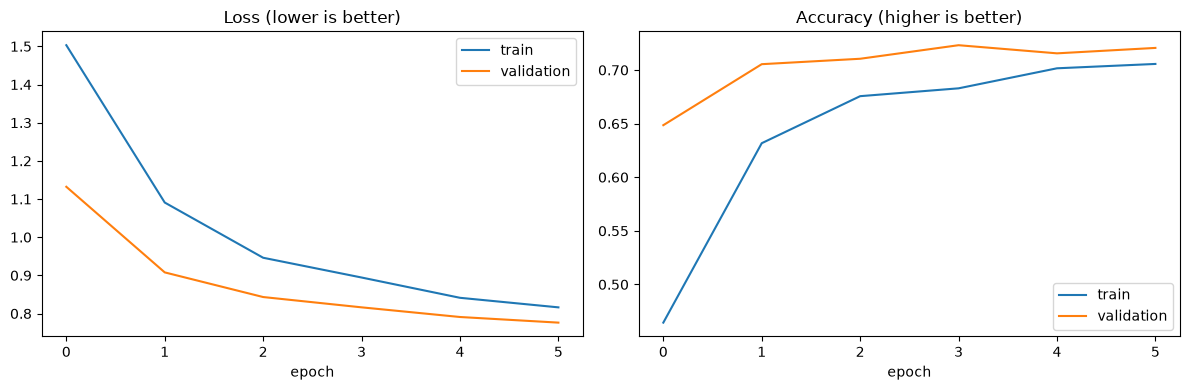

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="validation")
axes[0].set_title("Loss (lower is better)")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="validation")
axes[1].set_title("Accuracy (higher is better)")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


## 11. Final evaluation on the test set

**What we're doing here:** the test photos were never used for training or
for the epoch-by-epoch checks above - this is the one honest, unbiased
score for how well the model would do on brand-new tea leaf photos. We look
at:
- **overall accuracy**: fraction of test photos guessed correctly
- **classification report**: precision/recall/F1 per class, so we can see
  if one disease is harder to spot than the others
- **confusion matrix**: which classes get mixed up with which


In [92]:
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(labels.numpy())

test_accuracy = accuracy_score(all_true, all_preds)
report_text = classification_report(all_true, all_preds, target_names=class_names)
print(f"Test accuracy: {test_accuracy:.3f}\n")
print(report_text)

# The one number we'd compare across runs to pick a winner, plus the full
# per-class report saved as a run artifact (not just printed to a cell
# output that disappears once the notebook is re-run).
mlflow.log_metric("test_accuracy", test_accuracy)
mlflow.log_text(report_text, "classification_report.txt")


Test accuracy: 0.713

                        precision    recall  f1-score   support

1. Tea algal leaf spot       0.53      0.66      0.59        62
       2. Brown Blight       0.58      0.50      0.54        76
        3. Gray Blight       0.79      0.61      0.69       152
         4. Helopeltis       0.54      0.81      0.65        91
         5. Red spider       0.63      0.65      0.64        77
    6. Green mirid bug       0.83      0.75      0.78       193
       7. Healthy leaf       0.89      0.89      0.89       141

              accuracy                           0.71       792
             macro avg       0.68      0.70      0.68       792
          weighted avg       0.73      0.71      0.72       792



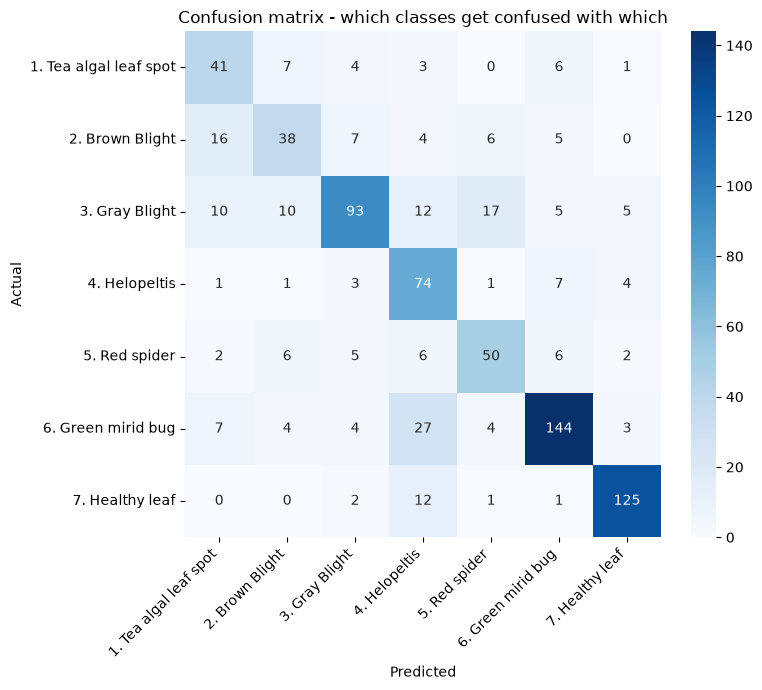

In [93]:
cm = confusion_matrix(all_true, all_preds)
fig = plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix - which classes get confused with which")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
mlflow.log_figure(fig, "confusion_matrix.png")
plt.show()


## 12. Save the trained model as a pickle file

**What we're doing here:** saving everything a future script would need to
reuse this model - the trained network itself, the list of class names (so
"index 3" can be turned back into "4. Helopeltis"), and the image size/
normalisation settings used during training - into one `.pkl` file with
Python's `pickle` module. Anyone loading this file later gets a ready-to-use
model without re-running any of the steps above.


In [94]:
import pickle

model_cpu = model.to("cpu")
model_cpu.eval()

bundle = {
    "model": model_cpu,
    "class_names": class_names,
    "img_size": IMG_SIZE,
    "normalize_mean": IMAGENET_MEAN,
    "normalize_std": IMAGENET_STD,
    "test_accuracy": test_accuracy,
}

OUTPUT_PATH = MODEL_DIR / "tea_disease_resnet18.pkl"
with open(OUTPUT_PATH, "wb") as f:
    pickle.dump(bundle, f)

print(f"Saved trained model to: {OUTPUT_PATH.resolve()}")

# Keep the flat .pkl as-is (that's what the chatbot's loader still reads),
# but also attach it to this run and register the underlying torch model so
# it gets a tracked version number (v1, v2, ...) instead of a file that just
# gets silently overwritten next time someone reruns this notebook.
# serialization_format="pickle": MLflow's newer default ("pt2") traces the
# model graph and needs a sample input for that - we don't need a traced
# graph here, just the same plain pickle the chatbot already knows how to load.
mlflow.log_artifact(str(OUTPUT_PATH), artifact_path="bundle")
mlflow.pytorch.log_model(
    model_cpu,
    artifact_path="model",
    registered_model_name="tea-disease-resnet18",
    serialization_format="pickle",
)

run_id = run.info.run_id
mlflow.end_run()
print(f"\nMLflow run finished: {run_id}")
print('From "ML Models/mlflow", run `mlflow ui --backend-store-uri sqlite:///mlflow.db` to '
      "compare runs across both this project and the fertilizer one, and see registered "
      "model versions.")


2026/10/14 19:52:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/14 19:52:17 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Saved trained model to: C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Disease Classification\model\tea_disease_resnet18.pkl


2026/10/14 19:52:17 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/14 19:52:27 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.29.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torchvision==0.29.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
Registered model 'tea-disease-resnet18' already exists. Creating a new version of this model...
Created version '2' of model 'tea-disease-resnet18'.



MLflow run finished: 0a0371a5ae0740d1a792e02dd3ff8b7f
From "ML Models/mlflow", run `mlflow ui --backend-store-uri sqlite:///mlflow.db` to compare runs across both this project and the fertilizer one, and see registered model versions.


## 13. Quick sanity check: load the pickle file back and predict one photo

**What we're doing here:** proving the saved file actually works on its own
- load it fresh from disk (like a different script would), pick one test
photo, and check the predicted class matches what we'd expect.


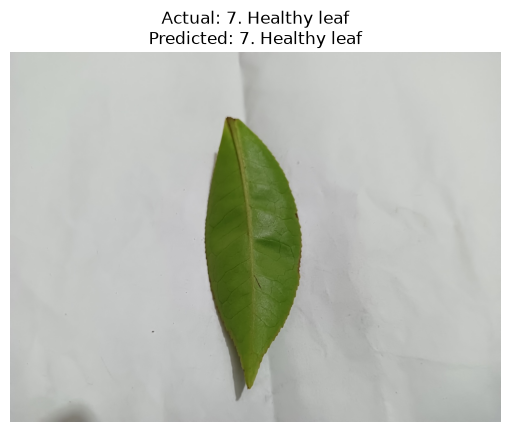

In [95]:
with open(OUTPUT_PATH, "rb") as f:
    loaded = pickle.load(f)

loaded_model = loaded["model"]
loaded_classes = loaded["class_names"]
predict_transform = transforms.Compose([
    transforms.Resize((loaded["img_size"], loaded["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(loaded["normalize_mean"], loaded["normalize_std"]),
])

sample_path = test_paths[0]
sample_label = loaded_classes[test_labels[0]]

img = Image.open(sample_path).convert("RGB")
input_tensor = predict_transform(img).unsqueeze(0)

loaded_model.eval()
with torch.no_grad():
    output = loaded_model(input_tensor)
    predicted = loaded_classes[output.argmax(1).item()]

plt.imshow(img)
plt.axis("off")
plt.title(f"Actual: {sample_label}\nPredicted: {predicted}")
plt.show()


## Summary - what happened in this notebook, in one paragraph

We looked at 7 folders of tea leaf photos (1 healthy, 6 disease/pest
classes) and split them into train/validation/test piles. We randomly
tweaked the training photos (flip/rotate/brightness) so the model learns
the pattern of each disease rather than memorising exact pictures. We took
a ResNet18 model that already knows how to "see" general photos, locked its
knowledge in place, and only trained a small new final layer to map what it
sees onto our 7 tea-leaf categories. We tracked accuracy after every epoch,
kept the best version, scored it once on photos it had never seen, and
saved that model to a `.pkl` file so it can be loaded and used elsewhere
(for example, by the Tea Support Assistant chatbot) without repeating any of
these steps.


## 14. Using what MLflow just recorded

This run is now saved in the **shared** tracking store at
`ML Models/mlflow/mlflow.db` - the same store the fertilizer dosage
notebook uses, under a different experiment. One server, multiple
projects. To see it:

```
cd "ML Models/mlflow"
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Open <http://127.0.0.1:5000>. You'll see:

- **Experiments -> tea-disease-classification** - one row per run, with
  `test_accuracy` and `best_val_acc` as sortable columns. Change `EPOCHS`
  or `LEARNING_RATE` above and rerun the notebook from section 8b onward -
  a second row appears instead of overwriting the first. The fertilizer
  model's runs show up under a separate `tea-fertilizer-dosage` experiment
  in the same sidebar - switch between them there instead of switching
  servers.
- **Models -> tea-disease-resnet18** - the registered model, with a new
  version (v1, v2, ...) each time this notebook finishes a run. Click a
  version to see which run produced it and what its metrics were.

There's no "best" version chosen automatically - that's a judgment call.
Once you've compared runs, you'd mark the one you trust by setting an
alias (e.g. `champion`) on that version, either in the UI or with
`mlflow.client.MlflowClient().set_registered_model_alias(...)`. That alias
is what a serving script would ask for, instead of hardcoding a version
number.

**What this doesn't do yet:** the chatbot's loader
(`Chat_Bot/agent/agents/disease/tools/leaf_image_classifier.py`) still
reads the flat `.pkl` directly - it has no idea the registry exists. Wiring
it up to pull "the current `champion` version" from the registry instead
is the natural next step, but it's a separate change to production code,
not something to bolt on here.


## 15. A different kind of tracking: tracing a single prediction

Everything above - params, metrics, the registered model - is about
**training runs**: one row per time you ran this notebook. **Tracing** is
about a single **prediction** happening live: what photo it was given,
what it guessed, and how long it took. For a one-step pipeline like this
one that's a fairly short story, but the same mechanism is what you'd
reach for to see every intermediate step in something more complex (an
agent calling several tools, say - this repo's own chatbot already builds
a hand-rolled version of exactly that idea in
`Chat_Bot/observability/callbacks.py` + its own SQLite trace store).
MLflow's tracing is the standardized, built-in version of that same idea,
and it lives in the same MLflow UI you've already been using - under a
**Traces** tab, separate from **Runs** and **Models**.

No new setup needed: tracing uses whatever tracking URI and experiment are
already active (set back in section 8b), so it lands in the
`tea-disease-classification` experiment automatically.


In [96]:
from mlflow.entities import SpanType

@mlflow.trace(span_type=SpanType.TOOL, name="predict_leaf_disease")
def predict_leaf(image_path: str) -> str:
    img = Image.open(image_path).convert("RGB")
    input_tensor = predict_transform(img).unsqueeze(0)
    loaded_model.eval()
    with torch.no_grad():
        output = loaded_model(input_tensor)
    return loaded_classes[output.argmax(1).item()]


# Call it on a few test photos - each call is one trace.
for path in test_paths[:3]:
    predicted = predict_leaf(path)
    print(f"{Path(path).name} -> {predicted}")


healthy_00330.jpg -> 7. Healthy leaf
helopeltis_00132.jpg -> 4. Helopeltis
green_mirid_bug_00516.jpg -> 6. Green mirid bug


## 16. Reading a trace back in code

**What we're doing here:** proving the trace actually recorded something,
the same way section 13 proved the saved model file worked - by reading it
back, not just assuming the decorator did its job.
`mlflow.get_last_active_trace_id()` gives the ID of whatever trace was
just created in this process; `mlflow.get_trace()` fetches it, and each
call's inputs/outputs/latency show up as a **span** inside it.


In [97]:
mlflow.flush_trace_async_logging()  # make sure the trace is actually written before reading it back

trace_id = mlflow.get_last_active_trace_id()
trace = mlflow.get_trace(trace_id)

print(f"Trace {trace.info.trace_id}  status={trace.info.state}")
for span in trace.data.spans:
    print(f"  span: {span.name} ({span.span_type})")
    print(f"    inputs:  {span.inputs}")
    print(f"    outputs: {span.outputs}")


Trace tr-972a846916419f828b9d2434e465e150  status=OK
  span: predict_leaf_disease (TOOL)
    inputs:  {'image_path': 'dataset\\data\\teaLeafBD\\teaLeafBD\\6. Green mirid bug\\green_mirid_bug_00516.jpg'}
    outputs: 6. Green mirid bug


## 17. Viewing traces in the UI

From `ML Models/mlflow` (with `mlflow ui --backend-store-uri sqlite:///mlflow.db`
running): open the `tea-disease-classification` experiment and click its
**Traces** tab, next to **Runs**. You'll see one row per `predict_leaf`
call above, each with its latency and a preview of its inputs/outputs -
click a row for the full span detail.

This is also exactly how you'd trace the chatbot's disease-detection path
in production, once it actually uses this classifier (see the note at the
end of section 14) instead of today's RAG + web search: wrap the
prediction call in `@mlflow.trace` the same way, and every real user photo
becomes a row here.
